# Operator Learning on the poisson model
1. The poisson model and numerical solver
2. Generating samples for the initial condition (via GP)
3. Train a FNO

## 1. The poisson model and numerical solver

L∞ error: 8.233e-05


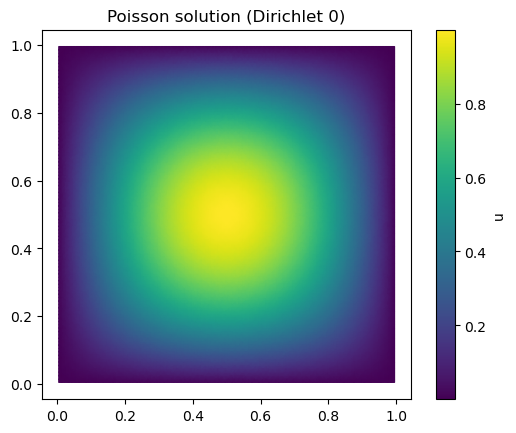

In [1]:
from fipy import Grid2D, CellVariable, DiffusionTerm, numerix as np
import numpy as onp
import matplotlib.pyplot as plt

N = 100
L = 1.0
dx = L / N
mesh = Grid2D(nx=N, ny=N, dx=dx, dy=dx)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 2 * np.pi**2 * np.sin(np.pi*xc) * np.sin(np.pi*yc)
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

u_exact = np.sin(np.pi*xc) * np.sin(np.pi*yc)
err_Linf = onp.max(onp.abs(u.value - u_exact))
print(f"L∞ error: {err_Linf:.3e}")

plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()



In [2]:
print(f_cv.shape)

(10000,)


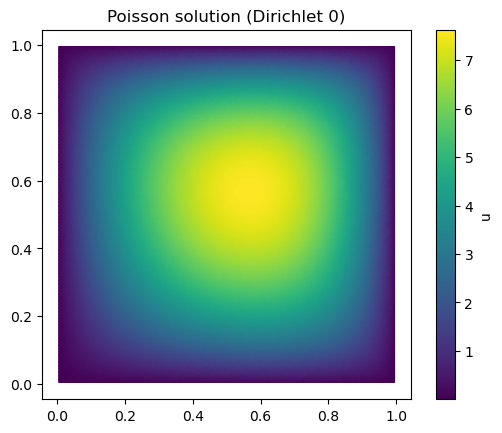

In [3]:
u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 100*xc + 100 * yc
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)


plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()

## 2. Generate samples for initial condition of the problem
To generate samples, we take a Gaussian process.

In [4]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
from typing import Tuple

import jax
import jax.numpy as jnp
from jaxtyping import Float, Array

# --- stability: 64-bit helps Cholesky on larger grids ---
jax.config.update("jax_enable_x64", True)

@dataclass
class Gaussian:
    mu: Float[Array, "N"]
    Sigma: Float[Array, "N N"]
    jitter: float = 1e-6

    @cached_property
    def L(self) -> Float[Array, "N N"]:
        n = self.Sigma.shape[0]
        # enforce symmetry (tiny fp errors can hurt Cholesky)
        S = 0.5 * (self.Sigma + self.Sigma.T)
        return jnp.linalg.cholesky(S + self.jitter * jnp.eye(n, dtype=S.dtype))

    def sample(self, key: jax.random.KeyArray, num_samples: int = 1
               ) -> Float[Array, "num_samples N"]:
        n = self.mu.shape[0]
        z = jax.random.normal(key, shape=(num_samples, n), dtype=self.mu.dtype)
        return self.mu + z @ self.L.T


def rbf_kernel(
    X: Float[Array, "N 2"], Y: Float[Array, "M 2"],
    variance: float = 1.0, lengthscales: Tuple[float, float] = (0.2, 0.2),
    dtype=jnp.float64
) -> Float[Array, "N M"]:
    ℓx, ℓy = lengthscales
    Xs = X / jnp.array([ℓx, ℓy], dtype=dtype)
    Ys = Y / jnp.array([ℓx, ℓy], dtype=dtype)
    diff = Xs[:, None, :] - Ys[None, :, :]
    sqdist = jnp.sum(diff * diff, axis=-1)
    return jnp.asarray(variance, dtype=dtype) * jnp.exp(-0.5 * sqdist)


def sample_gp_on_grid(
    key: jax.random.KeyArray,
    nx: int = 80, ny: int = 80,
    xlim=(0.0, 1.0), ylim=(0.0, 1.0),
    variance: float = 1.0, lengthscales=(0.15, 0.25),
    jitter: float = 1e-5, num_samples: int = 1,
    dtype=jnp.float64
):
    xs = jnp.linspace(xlim[0], xlim[1], nx, dtype=dtype)
    ys = jnp.linspace(ylim[0], ylim[1], ny, dtype=dtype)
    Xg, Yg = jnp.meshgrid(xs, ys, indexing="xy")       # (ny, nx)
    XY = jnp.stack([Xg.ravel(), Yg.ravel()], axis=-1)  # (N,2), N=nx*ny

    K = rbf_kernel(XY, XY, variance=variance, lengthscales=lengthscales, dtype=dtype)
    mu = jnp.zeros(K.shape[0], dtype=dtype)
    gp = Gaussian(mu=mu, Sigma=K, jitter=jitter)

    key, sub = jax.random.split(key)
    samples_flat = gp.sample(sub, num_samples=num_samples)         # (S, N)
    samples_img = samples_flat.reshape(num_samples, ny, nx)        # (S, ny, nx)
    return samples_img, xs, ys


In [5]:
# Plot of a gp sample

import numpy as onp
import matplotlib.pyplot as plt

key = jax.random.PRNGKey(356)  # <-- correct key ctor

min: -4.393014899326931 max: 4.923566512901655 std: 2.1634213001926264 has_nan: False


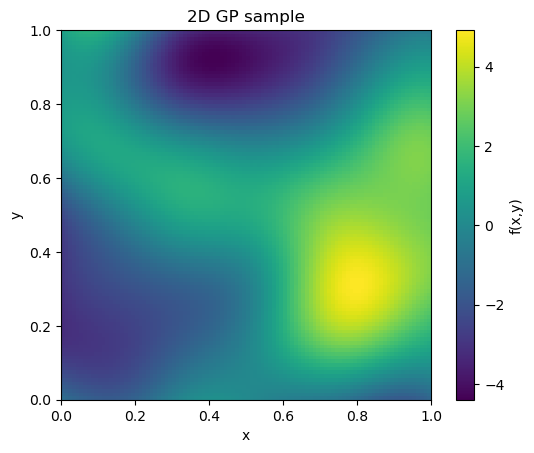

In [6]:
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.2, 0.2),
    jitter=1e-5, num_samples=1
)
s0 = onp.array(samples[2])  # to NumPy for plotting
print("min:", onp.nanmin(s0), "max:", onp.nanmax(s0), "std:", onp.nanstd(s0),
          "has_nan:", onp.isnan(s0).any())

# simplest, robust visualization:
plt.figure()
plt.imshow(s0, origin="lower", extent=[float(xs[0]), float(xs[-1]), float(ys[0]), float(ys[-1])], aspect="equal")
plt.colorbar(label="f(x,y)")
plt.title("2D GP sample")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

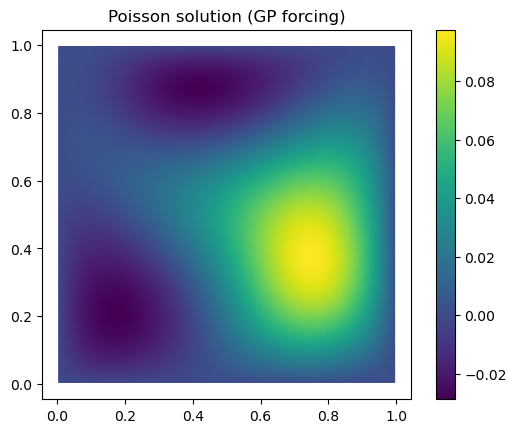

In [7]:
# s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
s_flat = onp.asarray(s0).ravel(order="C")              # length = N*N
assert s_flat.size == mesh.numberOfCells

f_cv = CellVariable(mesh=mesh, value=s_flat)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)
eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

# Plot
plt.figure()
plt.tripcolor(*mesh.cellCenters, u.value, shading="gouraud")
plt.colorbar(); plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (GP forcing)")
plt.show()

### Generate Dataset
We generate the Training data by sampling the initial condition from a Gaussian process and then solve the pde numerically

In [8]:
num_samples = 1000
frac_train = 0.7
solution = np.zeros(shape=(num_samples,N,N))
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=num_samples
)
for i in range(len(samples)):
    s = onp.array(samples[i])  # to NumPy for plotting
    # s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
    s_flat = onp.asarray(s).ravel(order="C")              # length = N*N
    assert s_flat.size == mesh.numberOfCells

    f_cv = CellVariable(mesh=mesh, value=s_flat)

    u = CellVariable(name="u", mesh=mesh, value=0.0)
    u.constrain(0.0, where=mesh.exteriorFaces)
    eq = DiffusionTerm(var=u) == -f_cv
    eq.solve(var=u)
    u_grid = u.value.reshape((N, N), order="C")  # shape back to grid
    solution[i] = u_grid
    

## 3. Train a FNO on the Dataset

In [9]:
# fno2d_train.py
from __future__ import annotations
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn import BatchNorm2d



In [10]:
# -----------------------------
# Dataset / Normalization
# -----------------------------
class GridPairDataset(Dataset):
    def __init__(self, X, Y, add_xy=True, normalize=True):
        assert X.shape == Y.shape and X.ndim == 3, "Expect (B, N, N)"
        self.X = torch.from_numpy(X)
        self.Y = torch.from_numpy(Y)
        self.add_xy = add_xy
        self.normalize = normalize

        # Stats for normalization (per-dataset scalar)
        if self.normalize:
            self.x_mean = self.X.mean()
            self.x_std  = self.X.std().clamp_min(1e-6)
            self.y_mean = self.Y.mean()
            self.y_std  = self.Y.std().clamp_min(1e-6)
        else:
            self.x_mean = self.x_std = self.y_mean = self.y_std = None

        # Pre-build positional grid (x,y) in [0,1]x[0,1]
        N = X.shape[1]
        xs = torch.linspace(0, 1, N)
        ys = torch.linspace(0, 1, N)
        Xg, Yg = torch.meshgrid(xs, ys, indexing="xy")
        self.xy = torch.stack([Xg, Yg], dim=0)  # (2, N, N)

    def __len__(self):
        return self.X.shape[0]
    
    def __shape__(self):
        return self.__shape__


    def __getitem__(self, idx):
        u0 = self.X[idx]  # (N,N)
        y  = self.Y[idx]  # (N,N)

        if self.normalize:
            u0 = (u0 - self.x_mean) / self.x_std
            y  = (y  - self.y_mean) / self.y_std

        u0 = u0.unsqueeze(0)  # (1,N,N)
        if self.add_xy:
            x_in = torch.cat([u0, self.xy], dim=0)  # (3,N,N): [u0, x, y]
        else:
            x_in = u0  # (1,N,N)

        return x_in, y.unsqueeze(0)  # input (C_in,N,N), target (1,N,N)
    def train_val_split(self, val_ratio=0.2, seed=None):
        """
        Split dataset into train/validation subsets.
        
        Args:
            val_ratio (float): Fraction of data to use for validation.
            seed (int, optional): Random seed for reproducibility.
        
        Returns:
            train_ds, val_ds (torch.utils.data.Dataset, torch.utils.data.Dataset)
        """
        n_total = len(self)
        n_val = int(n_total * val_ratio)
        n_train = n_total - n_val

        g = torch.Generator()
        if seed is not None:
            g.manual_seed(seed)

        train_ds, val_ds = random_split(self, [n_train, n_val], generator=g)
        return train_ds, val_ds




In [11]:
X, Y = onp.array(samples),onp.array(solution)
ds = GridPairDataset(X, Y, add_xy=True,  normalize=True)
train_ds, val_ds = ds.train_val_split(val_ratio=(1-frac_train))


In [43]:
width=64
modes=(16,16)
n_layers=5
epochs=200

In [44]:


# -----------------------------
# FNO2D components
# -----------------------------
class SpectralConv2d(nn.Module):
    """
    2D Fourier layer that keeps only low-frequency modes.
    """
    def __init__(self, in_channels, out_channels, modes_x: int, modes_y: int):
        super().__init__()
        self.in_channels  = in_channels
        self.out_channels = out_channels
        self.modes_x      = modes_x
        self.modes_y      = modes_y

        # Complex weights: (C_in, C_out, modes_x, modes_y)
        scale = 1.0 / (in_channels * out_channels)
        self.weight = nn.Parameter(
            (torch.randn(in_channels, out_channels, modes_x, modes_y) +
             1j * torch.randn(in_channels, out_channels, modes_x, modes_y)) * scale
        )  # dtype=torch.cfloat

    def forward(self, x):
        """
        x: (B, C_in, N, M) real
        returns: (B, C_out, N, M) real
        """
        B, C, N, M = x.shape

        # rFFT over last two dims -> (B, C, N, M//2+1) complex
        x_ft = torch.fft.rfft2(x, norm="ortho")

        # Output spectrum (complex)
        out_ft = torch.zeros(B, self.out_channels, N, M // 2 + 1,
                             dtype=torch.cfloat, device=x.device)

        mx = min(self.modes_x, N)
        my = min(self.modes_y, M // 2 + 1)

        # Low-frequency block: (B,C,mx,my) x (C,O,mx,my) -> (B,O,mx,my)
        out_ft[:, :, :mx, :my] = torch.einsum(
            "bcxy,coxy->boxy",
            x_ft[:, :, :mx, :my],
            self.weight[:, :, :mx, :my].to(x_ft.dtype).to(x.device),
        )

        # Back to real space
        x_out = torch.fft.irfft2(out_ft, s=(N, M), norm="ortho").real
        return x_out


class FNOBlock2d(nn.Module):
    def __init__(self, width, modes_x, modes_y):
        super().__init__()
        self.spectral = SpectralConv2d(width, width, modes_x, modes_y)
        self.w = nn.Conv2d(width, width, kernel_size=1)
        self.act = nn.GELU()
        self.width = width
        self.dropout = nn.Dropout(0.1)
        self.batch_norm = BatchNorm2d(self.width)

    def forward(self, x):
        x = self.spectral(x) + self.w(x)
        self.act(x)
        x = self.batch_norm(x)
        x = self.dropout(x)
        return x

class FNO2d(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, width=32, modes=(16,16), n_layers=3):
        super().__init__()
        self.width = width
        self.fc0 = nn.Conv2d(in_channels, width, kernel_size=1)   # lifting
        self.blocks = nn.ModuleList([FNOBlock2d(width, modes[0], modes[1]) for _ in range(n_layers)])
        self.fc1 = nn.Conv2d(width, width, kernel_size=1)
        self.fc2 = nn.Conv2d(width, out_channels, kernel_size=1)
        

    def forward(self, x):
        """
        x: (B, C_in, N, N)
        returns: (B, 1, N, N)
        """
        x = self.fc0(x)
        for blk in self.blocks:
            x = blk(x)
            
        x = nn.GELU()(self.fc1(x))
        x = self.fc2(x)
        return x




### Training loop

In [45]:
# -----------------------------
# Training loop
# -----------------------------
def train_fno2d(
    train_ds: Dataset,
    val_ds: Dataset,
    epochs=50,
    batch_size=8,
    lr=1e-5,
    width=16,
    modes=(12,12),
    n_layers=3,
    device=None,
    wd = 1e-6
):
    device = device or ("mps" if torch.backends.mps.is_available() else "cpu")
    print(f"Using device: {device}")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)

    model = FNO2d(in_channels=3, out_channels=1, width=width, modes=modes, n_layers=n_layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr,weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.StepLR(opt,step_size=15, gamma=0.01)
    loss_fn = nn.MSELoss()

    best_val = math.inf
    for ep in range(1, epochs+1):
        model.train()
        tr_loss = 0.0
        for x, y in train_loader:
            x = x.to(device, dtype=torch.float32)   # (B, 3, N, N)
            y = y.to(device, dtype=torch.float32)   # (B, 1, N, N)

            opt.zero_grad()
            pred = model(x)
            loss = loss_fn(pred, y)
            loss.backward()
            opt.step()
            tr_loss += loss.item() * x.size(0)

        tr_loss /= len(train_loader.dataset)

        model.eval()
        va_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x = x.to(device, dtype=torch.float32)
                y = y.to(device, dtype=torch.float32)
                pred = model(x)
                va_loss += loss_fn(pred, y).item() * x.size(0)
        va_loss /= len(val_loader.dataset)

        if va_loss < best_val:
            best_val = va_loss
            torch.save(model.state_dict(), "fno2d_best.pt")
        scheduler.step()
        print(f"[{ep:03d}/{epochs}] train {tr_loss:.4e}  val {va_loss:.4e}  (best {best_val:.4e}) lr: {scheduler.get_last_lr()[0]:.2e}")

    print("Training complete. Best model saved to fno2d_best.pt")
    return model




    

In [ ]:
model = train_fno2d(
        train_ds, val_ds,
        epochs=epochs, batch_size=32, lr=1e-3,
        width=width, modes=modes, n_layers=n_layers,wd = 1e-6
    )

Using device: mps
[001/200] train 6.3023e-01  val 6.2337e-01  (best 6.2337e-01) lr: 1.00e-03
[002/200] train 5.5559e-01  val 6.4178e-01  (best 6.2337e-01) lr: 1.00e-03
[003/200] train 5.1870e-01  val 5.4744e-01  (best 5.4744e-01) lr: 1.00e-03
[004/200] train 5.2686e-01  val 6.8021e-01  (best 5.4744e-01) lr: 1.00e-03
[005/200] train 5.8895e-01  val 6.4851e-01  (best 5.4744e-01) lr: 1.00e-03
[006/200] train 5.9784e-01  val 5.6607e-01  (best 5.4744e-01) lr: 1.00e-03
[007/200] train 5.9036e-01  val 5.5880e-01  (best 5.4744e-01) lr: 1.00e-03
[008/200] train 5.1396e-01  val 5.0843e-01  (best 5.0843e-01) lr: 1.00e-03
[009/200] train 5.2591e-01  val 5.4523e-01  (best 5.0843e-01) lr: 1.00e-03
[010/200] train 5.4949e-01  val 5.9646e-01  (best 5.0843e-01) lr: 1.00e-03
[011/200] train 5.5289e-01  val 5.1633e-01  (best 5.0843e-01) lr: 1.00e-03
[012/200] train 5.2152e-01  val 7.0004e-01  (best 5.0843e-01) lr: 1.00e-03
[013/200] train 6.6778e-01  val 7.6491e-01  (best 5.0843e-01) lr: 1.00e-03
[014/20

### Evaluation

In [20]:

# --- load the best model ---
model = FNO2d(in_channels=3, out_channels=1, width=width, modes=modes, n_layers=n_layers)

device = "mps" if torch.backends.mps.is_available() else "cpu"
model.load_state_dict(torch.load("fno2d_best.pt", map_location=device))
model = model.to(device)
model.eval()

# --- evaluation ---
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)
loss_fn = nn.MSELoss(reduction="mean")

total_loss = 0.0
num_samples = 0
with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device, dtype=torch.float32)  # (B,3,N,N)
        y = y.to(device, dtype=torch.float32)  # (B,1,N,N)
        pred = model(x)

        # accumulate MSE
        loss = loss_fn(pred, y).item()
        total_loss += loss * x.size(0)
        num_samples += x.size(0)

avg_mse = total_loss / num_samples
rmse = avg_mse ** 0.5
print(f"Validation MSE:  {avg_mse:.4e}")
print(f"Validation RMSE: {rmse:.4e}")

Validation MSE:  5.6528e-01
Validation RMSE: 7.5185e-01


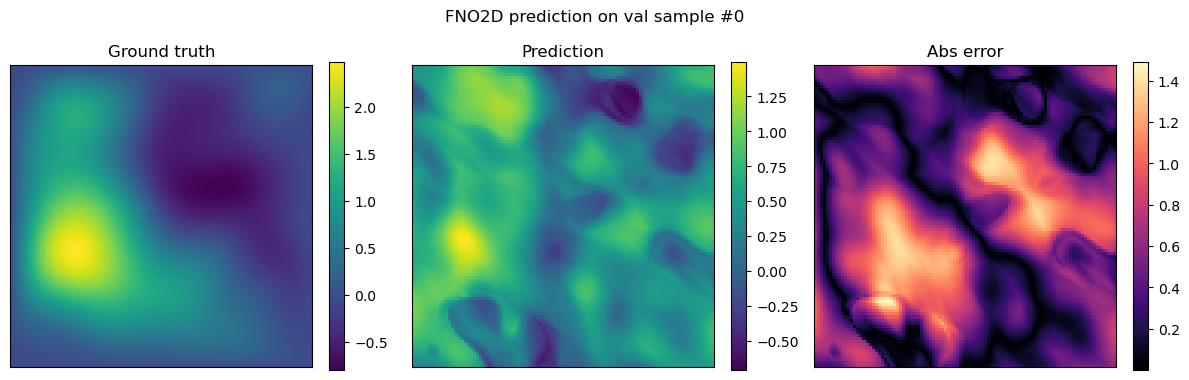

In [22]:
# --- pick one sample from val_ds ---
idx = 0  # choose which sample to visualize
x_in, y_true = val_ds[idx]      # shapes: (C_in,N,N), (1,N,N)
N = y_true.shape[-1]

x_in_t = x_in.unsqueeze(0).to(device, dtype=torch.float32)   # (1,C_in,N,N)
with torch.no_grad():
    y_pred_t = model(x_in_t)   # (1,1,N,N)

y_pred = y_pred_t.cpu().numpy()[0,0]   # (N,N)
y_true = y_true.numpy()[0]             # (N,N)

# --- plot ---
fig, axs = plt.subplots(1,3, figsize=(12,4))
im0 = axs[0].imshow(y_true, origin="lower", cmap="viridis")
axs[0].set_title("Ground truth")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(y_pred, origin="lower", cmap="viridis")
axs[1].set_title("Prediction")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

im2 = axs[2].imshow(np.abs(y_pred - y_true), origin="lower", cmap="magma")
axs[2].set_title("Abs error")
plt.colorbar(im2, ax=axs[2], fraction=0.046)

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"FNO2D prediction on val sample #{idx}")
plt.tight_layout()